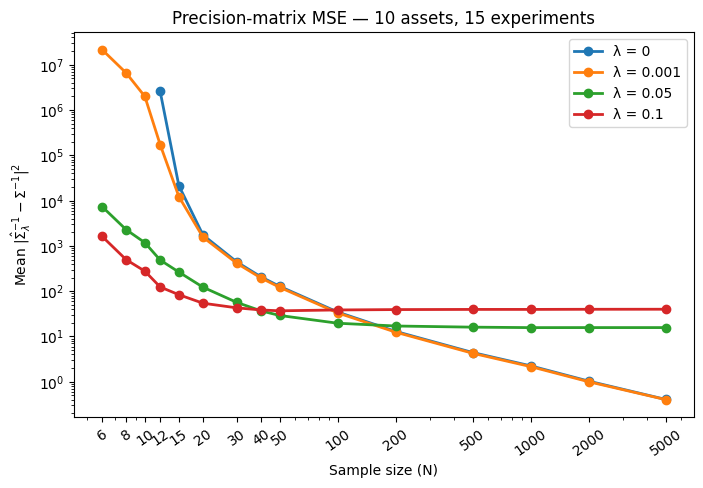

In [17]:
import numpy as np
import matplotlib.pyplot as plt

p = 10
Sigma = np.array(
    [
        [1.00, 0.80, 0.64, 0.51, 0.41, 0.33, 0.26, 0.21, 0.17, 0.13],
        [0.80, 1.00, 0.80, 0.64, 0.51, 0.41, 0.33, 0.26, 0.21, 0.17],
        [0.64, 0.80, 1.00, 0.80, 0.64, 0.51, 0.41, 0.33, 0.26, 0.21],
        [0.51, 0.64, 0.80, 1.00, 0.80, 0.64, 0.51, 0.41, 0.33, 0.26],
        [0.41, 0.51, 0.64, 0.80, 1.00, 0.80, 0.64, 0.51, 0.41, 0.33],
        [0.33, 0.41, 0.51, 0.64, 0.80, 1.00, 0.80, 0.64, 0.51, 0.41],
        [0.26, 0.33, 0.41, 0.51, 0.64, 0.80, 1.00, 0.80, 0.64, 0.51],
        [0.21, 0.26, 0.33, 0.41, 0.51, 0.64, 0.80, 1.00, 0.80, 0.64],
        [0.17, 0.21, 0.26, 0.33, 0.41, 0.51, 0.64, 0.80, 1.00, 0.80],
        [0.13, 0.17, 0.21, 0.26, 0.33, 0.41, 0.51, 0.64, 0.80, 1.00],
    ]
)
true_precision = np.linalg.inv(Sigma)

sample_sizes = [6, 8, 10, 12, 15, 20, 30, 40, 50, 100, 200, 500, 1000, 2000, 5000]
lambdas = [0.0, 0.001, 0.05, 0.1]
mse = {lam: [] for lam in lambdas}

for N in sample_sizes:
    errors = {lam: [] for lam in lambdas}
    for _ in range(50):
        X = np.random.multivariate_normal(np.zeros(10), Sigma, size=N)
        # X.shape is (N, p) where p = 10 is the number of assets.
        S = np.cov(X, rowvar=False)

        for lam in lambdas:
            # extract diagonal of S
            diag_S = np.diag(np.diag(S))
            shrunk_cov = (1 - lam) * S + lam * diag_S
            try:
                estimated_precision = np.linalg.inv(shrunk_cov)
            except np.linalg.LinAlgError:
                errors[lam].append(np.nan)
                continue
            errors[lam].append(
                np.linalg.norm(estimated_precision - true_precision) ** 2
            )

    for lam in lambdas:
        mse[lam].append(np.mean(errors[lam]) if errors[lam] else np.nan)

fig, ax = plt.subplots(figsize=(8, 5))
for lam in lambdas:
    ax.plot(sample_sizes, mse[lam], marker="o", linewidth=2, label=f"λ = {lam:g}")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks(sample_sizes, [str(N) for N in sample_sizes], rotation=35)
ax.set_xlabel("Sample size (N)")
ax.set_ylabel(r"Mean $\|\hat{\Sigma}_\lambda^{-1}-\Sigma^{-1}\|^2$")
ax.set_title("Precision-matrix MSE — 10 assets, 15 experiments")
ax.legend()
plt.show()

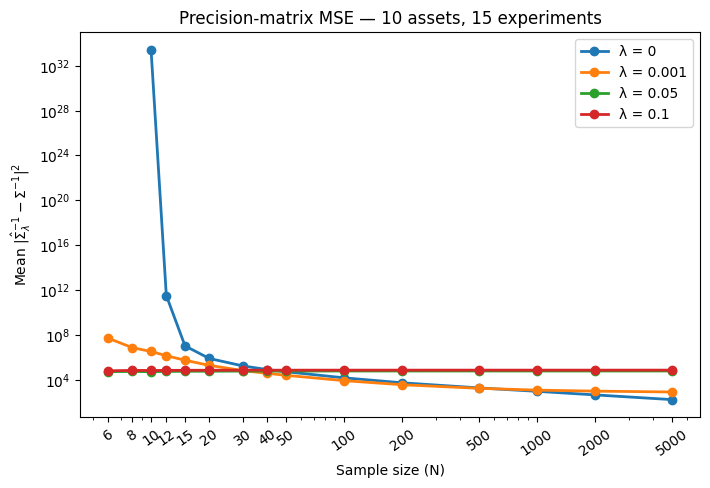

In [16]:
import numpy as np
import matplotlib.pyplot as plt

p = 10

Sigma = np.array(
    [
        [ 1.00,  0.99, -0.99,  0.99, -0.99,  0.99, -0.99,  0.99, -0.99, -0.99],
        [ 0.99,  1.00, -0.99,  0.99, -0.99,  0.99, -0.99,  0.99, -0.99, -0.99],
        [-0.99, -0.99,  1.00, -0.99,  0.99, -0.99,  0.99, -0.99,  0.99,  0.99],
        [ 0.99,  0.99, -0.99,  1.00, -0.99,  0.99, -0.99,  0.99, -0.99, -0.99],
        [-0.99, -0.99,  0.99, -0.99,  1.00, -0.99,  0.99, -0.99,  0.99,  0.99],
        [ 0.99,  0.99, -0.99,  0.99, -0.99,  1.00, -0.99,  0.99, -0.99, -0.99],
        [-0.99, -0.99,  0.99, -0.99,  0.99, -0.99,  1.00, -0.99,  0.99,  0.99],
        [ 0.99,  0.99, -0.99,  0.99, -0.99,  0.99, -0.99,  1.00, -0.99, -0.99],
        [-0.99, -0.99,  0.99, -0.99,  0.99, -0.99,  0.99, -0.99,  1.00,  0.99],
        [-0.99, -0.99,  0.99, -0.99,  0.99, -0.99,  0.99, -0.99,  0.99,  1.00],
    ]
)

true_precision = np.linalg.inv(Sigma)

sample_sizes = [6, 8, 10, 12, 15, 20, 30, 40, 50, 100, 200, 500, 1000, 2000, 5000]
lambdas = [0.0, 0.001, 0.05, 0.1]
mse = {lam: [] for lam in lambdas}

for N in sample_sizes:
    errors = {lam: [] for lam in lambdas}
    for _ in range(50):
        X = np.random.multivariate_normal(np.zeros(10), Sigma, size=N)
        # X.shape is (N, p) where p = 10 is the number of assets.
        S = np.cov(X, rowvar=False)

        for lam in lambdas:
            # extract diagonal of S
            diag_S = np.diag(np.diag(S))
            shrunk_cov = (1 - lam) * S + lam * diag_S
            try:
                estimated_precision = np.linalg.inv(shrunk_cov)
            except np.linalg.LinAlgError:
                errors[lam].append(np.nan)
                continue
            errors[lam].append(
                np.linalg.norm(estimated_precision - true_precision) ** 2
            )

    for lam in lambdas:
        mse[lam].append(np.mean(errors[lam]) if errors[lam] else np.nan)

fig, ax = plt.subplots(figsize=(8, 5))
for lam in lambdas:
    ax.plot(sample_sizes, mse[lam], marker="o", linewidth=2, label=f"λ = {lam:g}")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks(sample_sizes, [str(N) for N in sample_sizes], rotation=35)
ax.set_xlabel("Sample size (N)")
ax.set_ylabel(r"Mean $\|\hat{\Sigma}_\lambda^{-1}-\Sigma^{-1}\|^2$")
ax.set_title("Precision-matrix MSE — 10 assets, 15 experiments")
ax.legend()
plt.show()